In [24]:
import pandas as pd

df = pd.read_csv("lc_occupation_skills.csv")

jobs = (
    df.groupby(["onet", "onet_name"])["skill_name"]
    .apply(lambda skills: skills.dropna().unique().tolist())
    .reset_index(name="skills")
)

print(jobs.head())

# # Access a job and its skills
# first_job = jobs.iloc[0]
# print(first_job["onet_name"])
# print(first_job["skills"])

         onet                            onet_name  \
0  11-1011.00                     Chief Executives   
1  11-1011.03        Chief Sustainability Officers   
2  11-1021.00      General and Operations Managers   
3  11-2011.00  Advertising and Promotions Managers   
4  11-2021.00                   Marketing Managers   

                                              skills  
0  [Communication, Marketing, Financial Managemen...  
1  [Management, Leadership, Communication, Custom...  
2  [Leadership, Planning, Sales, Operations, Prob...  
3  [Certified Public Accountant, Influencing Skil...  
4  [Scalability, Project Management Professional ...  


Occupation-skill records: 23877
Unique occupations: 966
Records with valid replaceability scores: 23244
Records without valid scores: 633

Example occupations:
         onet                            onet_name
0  11-1011.00                     Chief Executives
1  11-1011.03        Chief Sustainability Officers
2  11-1021.00      General and Operations Managers
3  11-2011.00  Advertising and Promotions Managers
4  11-2021.00                   Marketing Managers


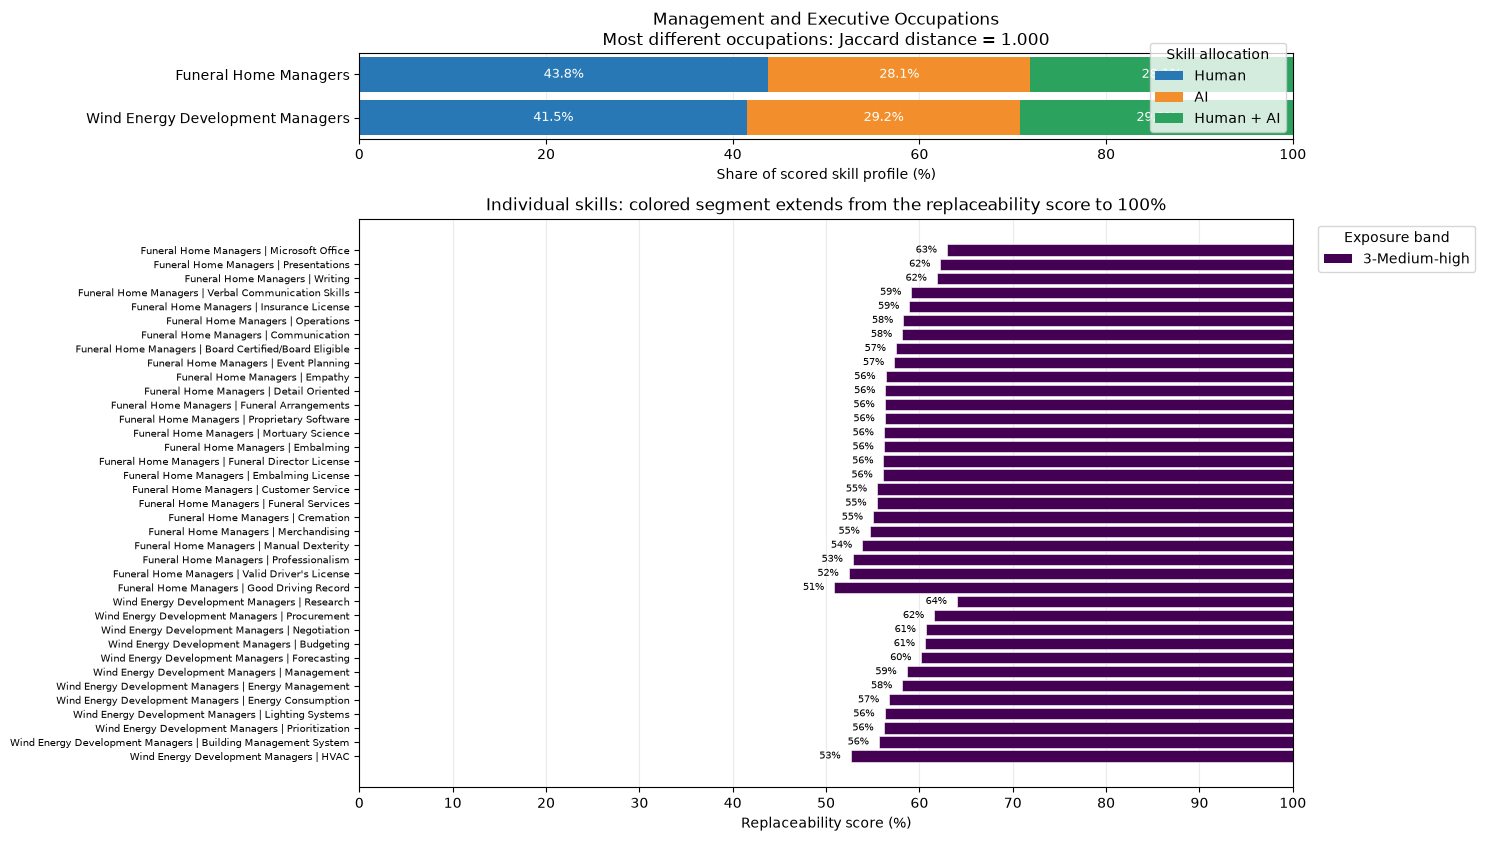


GROUP: Management and Executive Occupations
Jaccard distance: 1.000

Funeral Home Managers (11-9171.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%

Wind Energy Development Managers (11-9199.10)
Scored skills: 12 / 16
Share of original posting-weight covered by scored skills: 75.0%

Skills missing valid scores:
Electric Vehicles, Electricity, Energy Management Systems, Energy Systems


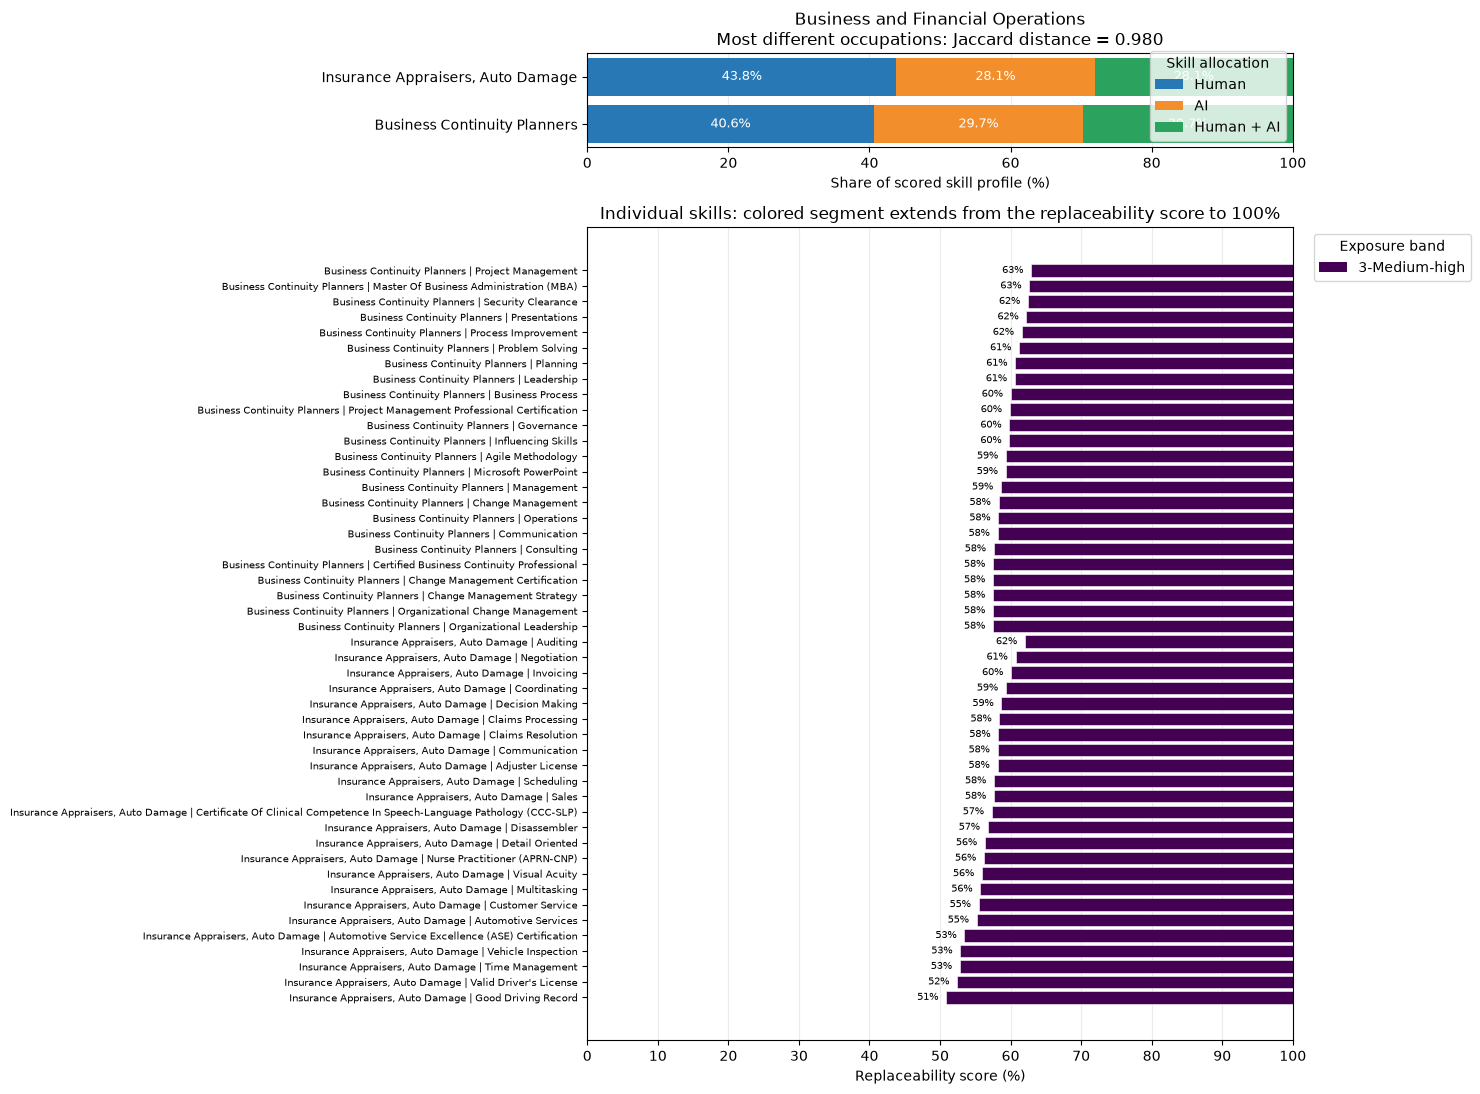


GROUP: Business and Financial Operations
Jaccard distance: 0.980

Insurance Appraisers, Auto Damage (13-1032.00)
Scored skills: 24 / 25
Share of original posting-weight covered by scored skills: 98.7%

Business Continuity Planners (13-1199.04)
Scored skills: 24 / 25
Share of original posting-weight covered by scored skills: 97.8%

Skills missing valid scores:
Change Management Planning, Xactimate (Claims Estimating Software)


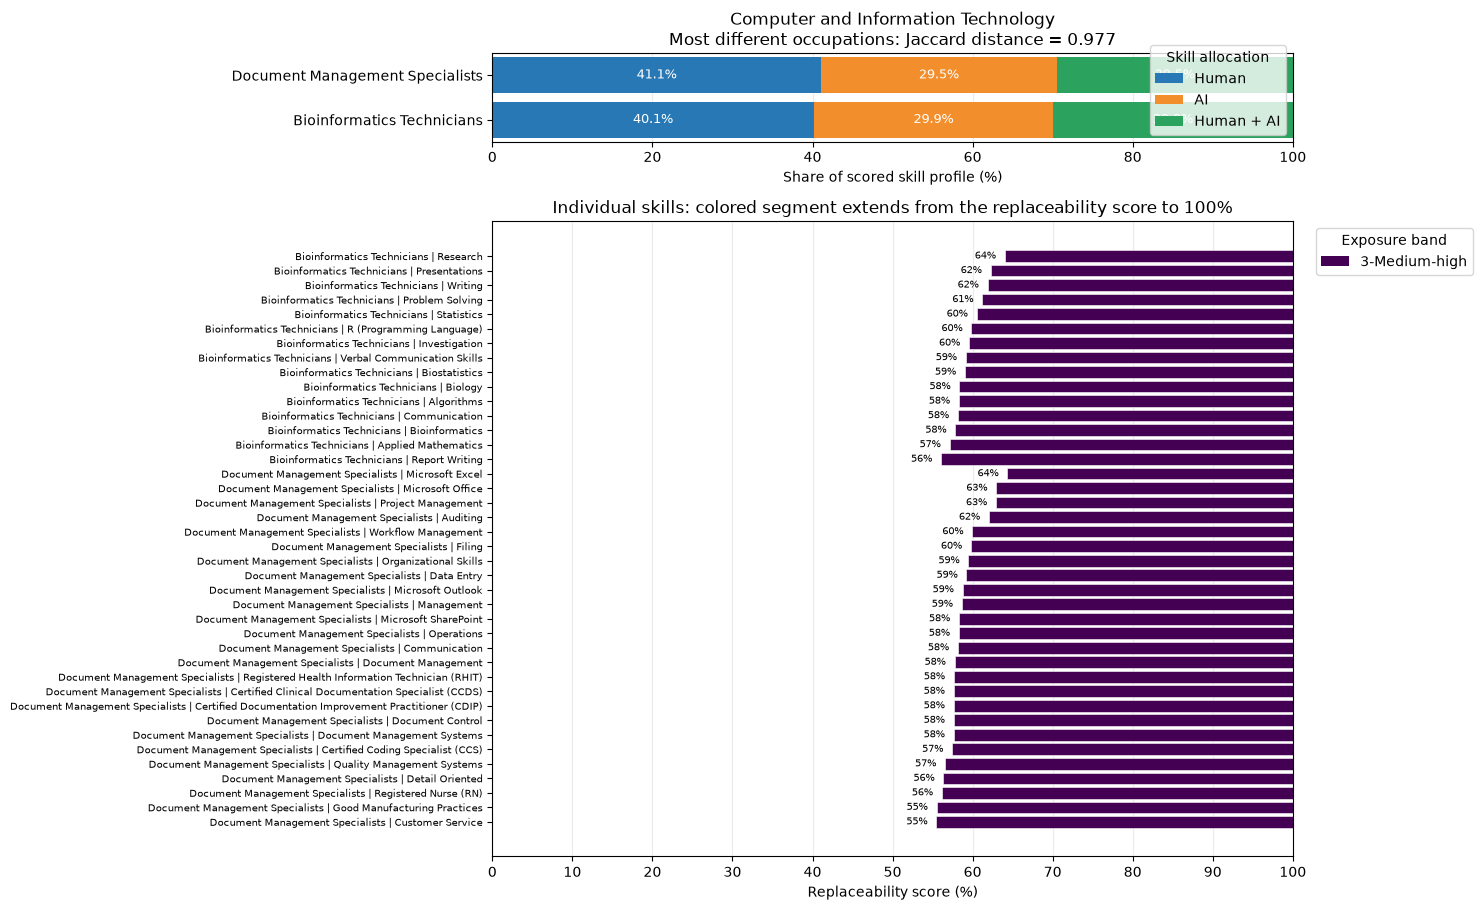


GROUP: Computer and Information Technology
Jaccard distance: 0.977

Document Management Specialists (15-1299.03)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%

Bioinformatics Technicians (15-2099.01)
Scored skills: 15 / 20
Share of original posting-weight covered by scored skills: 78.6%

Skills missing valid scores:
Adult Care, Analytical Thinking, Bayesian Statistics, Biomarkers, Proteomics


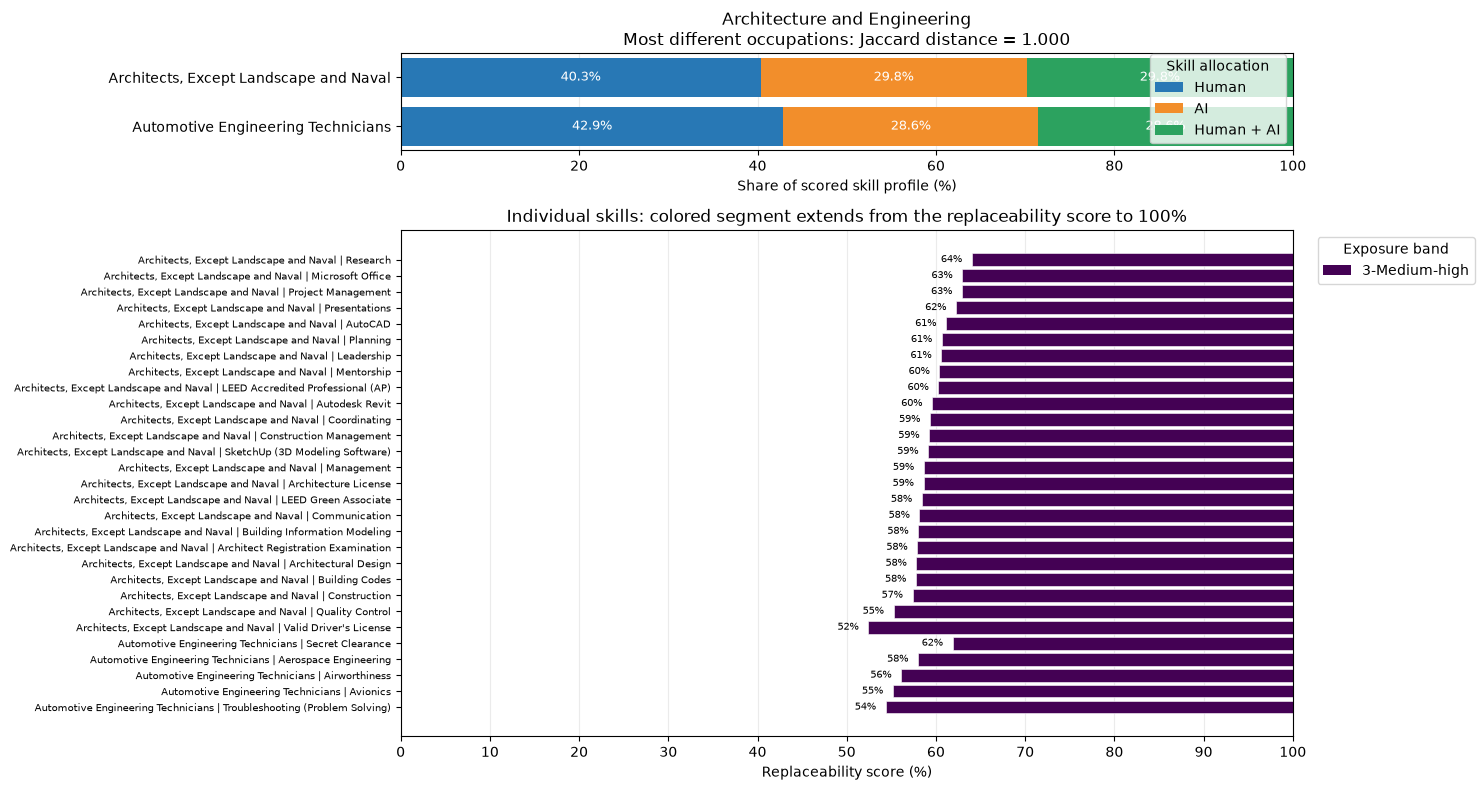


GROUP: Architecture and Engineering
Jaccard distance: 1.000

Architects, Except Landscape and Naval (17-1011.00)
Scored skills: 24 / 25
Share of original posting-weight covered by scored skills: 97.8%

Automotive Engineering Technicians (17-3027.01)
Scored skills: 5 / 12
Share of original posting-weight covered by scored skills: 41.7%

Skills missing valid scores:
Component Analysis, Data Processing, Environmental Control Systems Engineering, Flowmaster, Fluid Mechanics, Fuel Systems, Heat Transfer, Schematic Diagrams


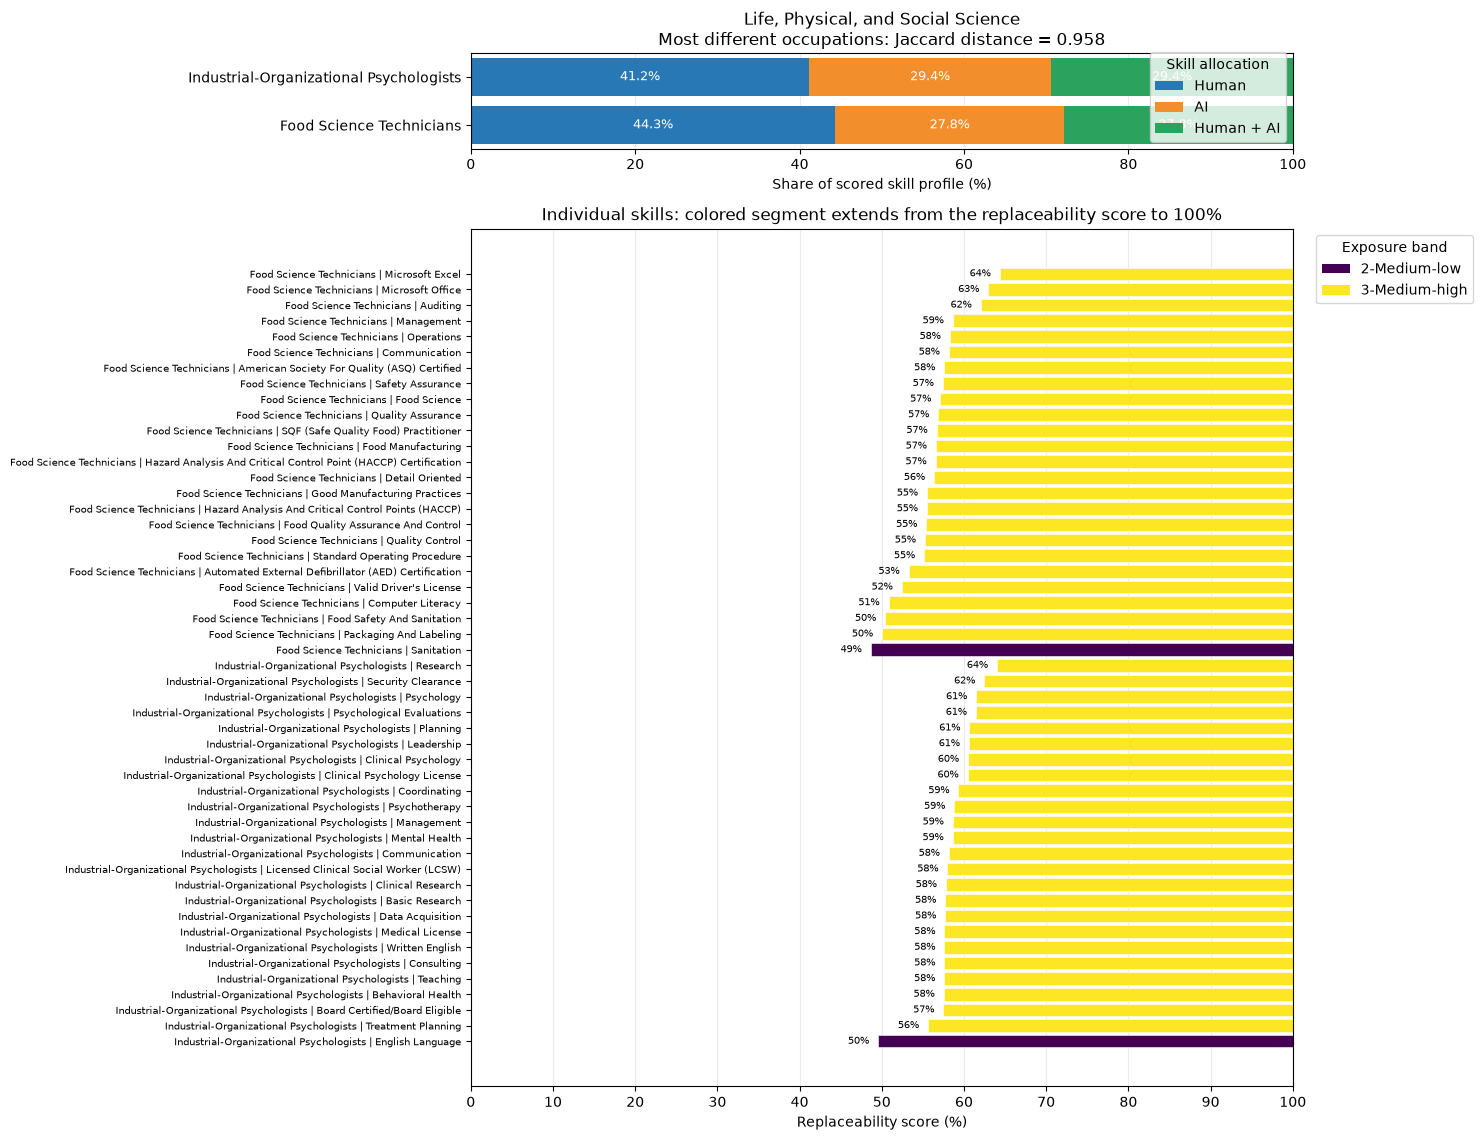


GROUP: Life, Physical, and Social Science
Jaccard distance: 0.958

Industrial-Organizational Psychologists (19-3032.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%

Food Science Technicians (19-4013.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%


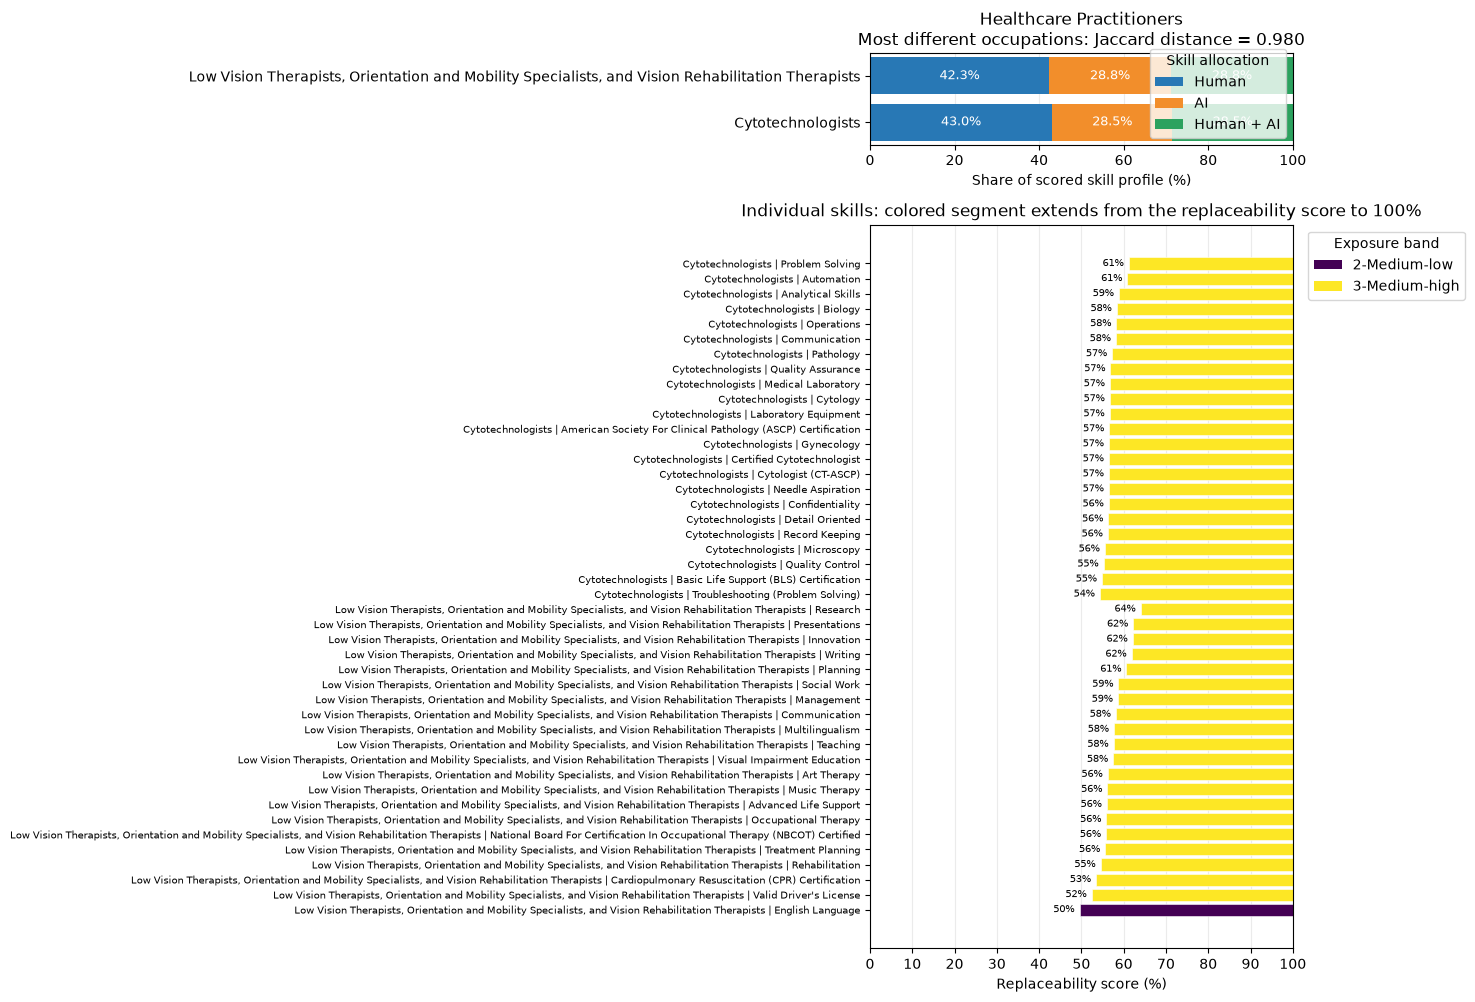


GROUP: Healthcare Practitioners
Jaccard distance: 0.980

Low Vision Therapists, Orientation and Mobility Specialists, and Vision Rehabilitation Therapists (29-1122.01)
Scored skills: 21 / 25
Share of original posting-weight covered by scored skills: 82.1%

Cytotechnologists (29-2011.02)
Scored skills: 23 / 25
Share of original posting-weight covered by scored skills: 96.6%

Skills missing valid scores:
Certified Vision Rehabilitation Therapist, Health Insurance Portability And Accountability Act (HIPAA) Compliance, Leisure And Recreation, Practicum, Specialist In Cytology (SCT-ASCP), Vision Rehabilitation


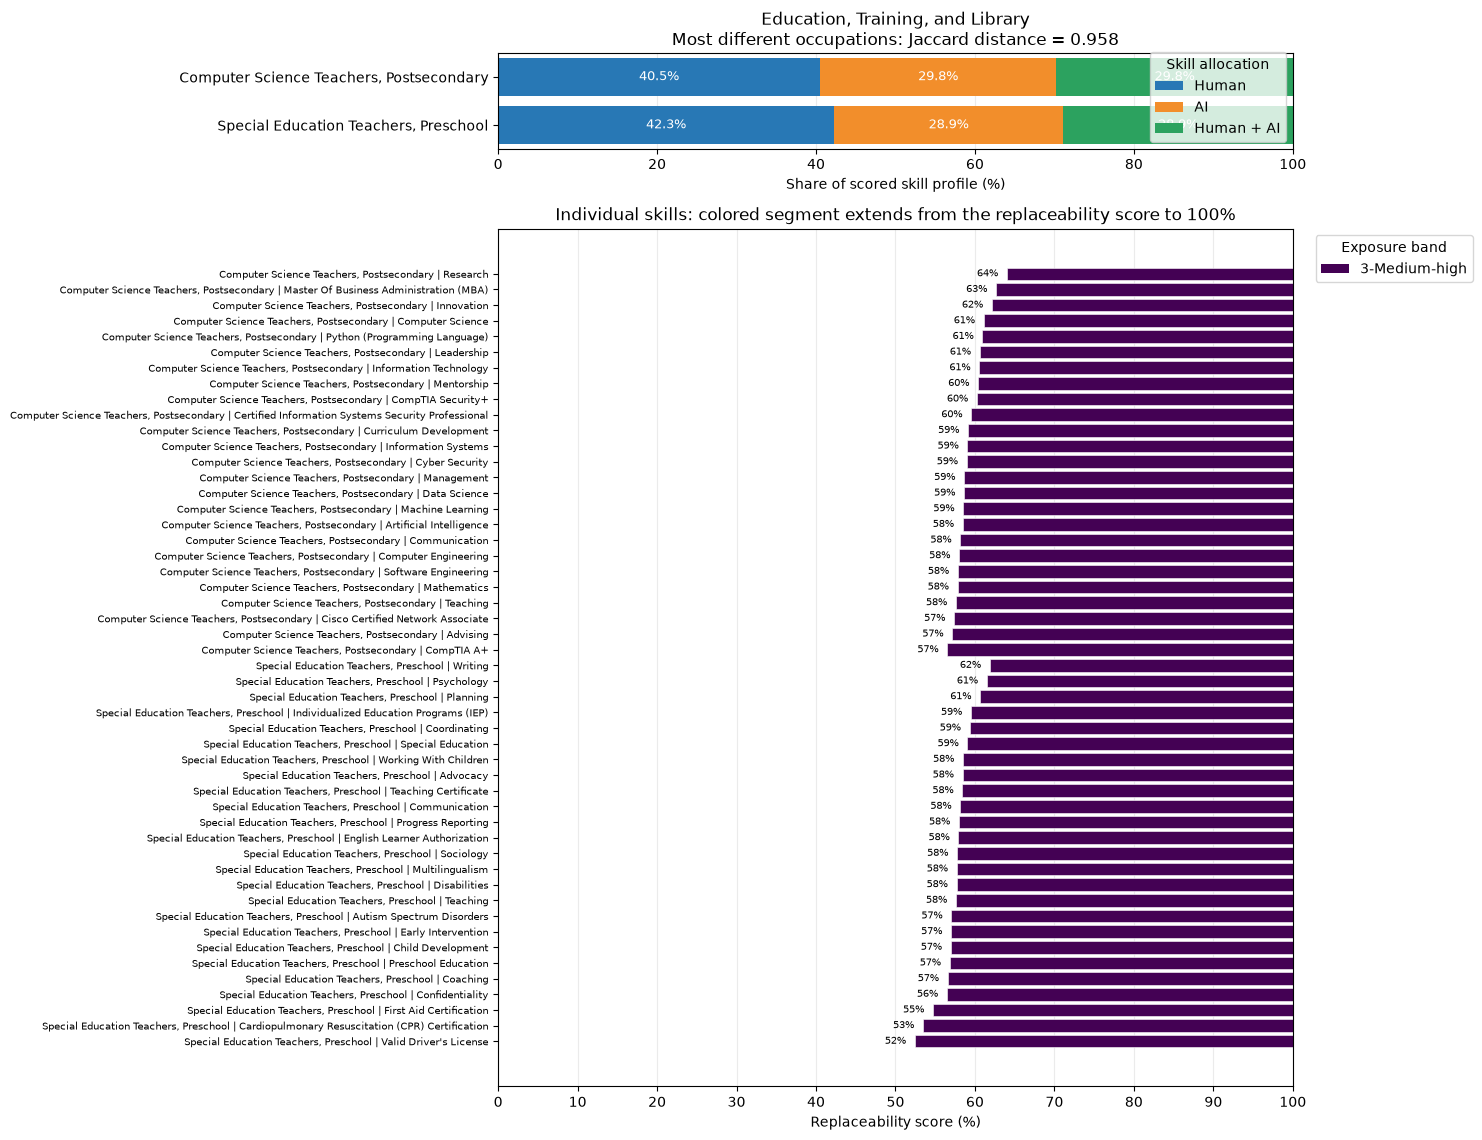


GROUP: Education, Training, and Library
Jaccard distance: 0.958

Computer Science Teachers, Postsecondary (25-1021.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%

Special Education Teachers, Preschool (25-2051.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%


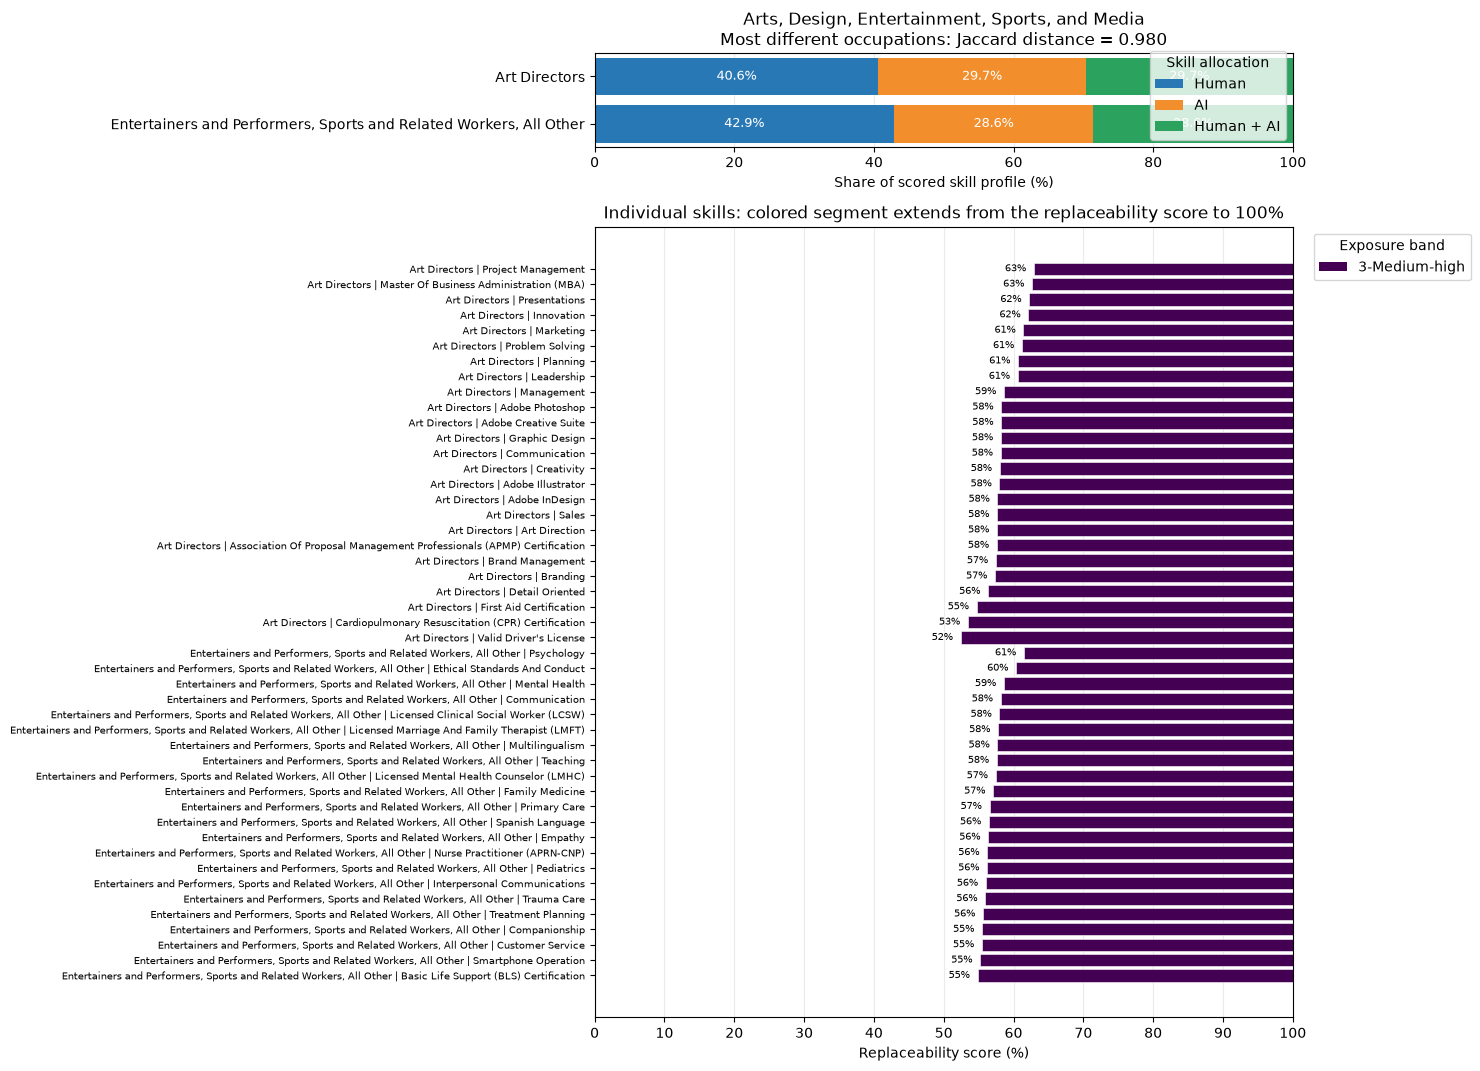


GROUP: Arts, Design, Entertainment, Sports, and Media
Jaccard distance: 0.980

Art Directors (27-1011.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%

Entertainers and Performers, Sports and Related Workers, All Other (27-2099.00)
Scored skills: 22 / 25
Share of original posting-weight covered by scored skills: 81.9%

Skills missing valid scores:
Advertisement, Mobility Assistance, Web Conferencing


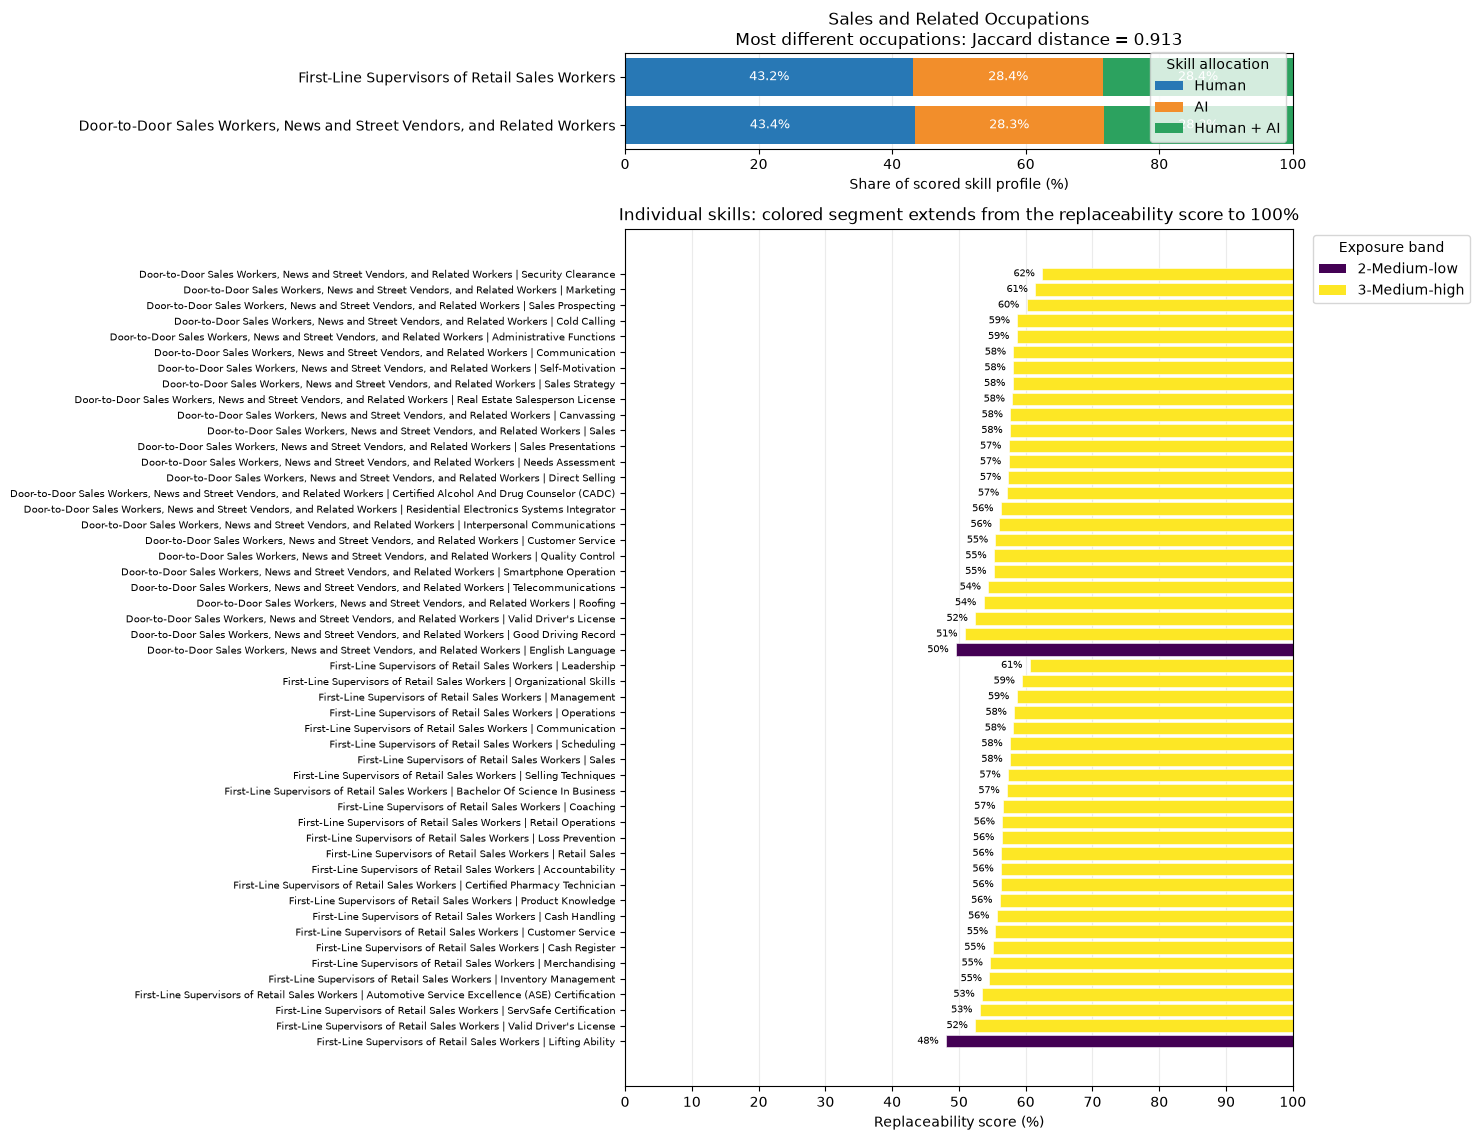


GROUP: Sales and Related Occupations
Jaccard distance: 0.913

First-Line Supervisors of Retail Sales Workers (41-1011.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%

Door-to-Door Sales Workers, News and Street Vendors, and Related Workers (41-9091.00)
Scored skills: 25 / 25
Share of original posting-weight covered by scored skills: 100.0%


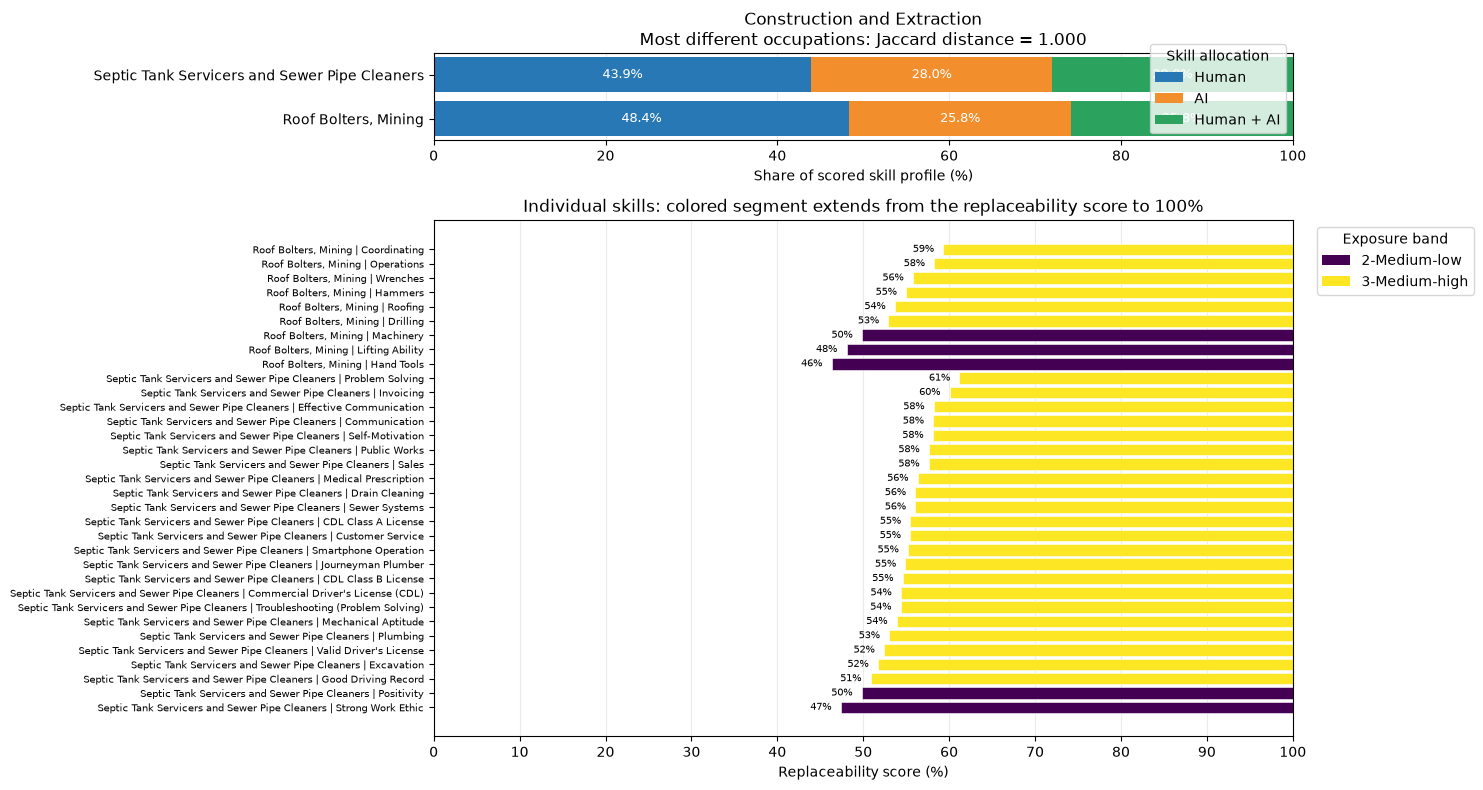


GROUP: Construction and Extraction
Jaccard distance: 1.000

Septic Tank Servicers and Sewer Pipe Cleaners (47-4071.00)
Scored skills: 24 / 25
Share of original posting-weight covered by scored skills: 99.5%

Roof Bolters, Mining (47-5043.00)
Scored skills: 9 / 12
Share of original posting-weight covered by scored skills: 67.6%

Skills missing valid scores:
Listening Skills, Roof Bolting, Torque Wrench, Underground Mining


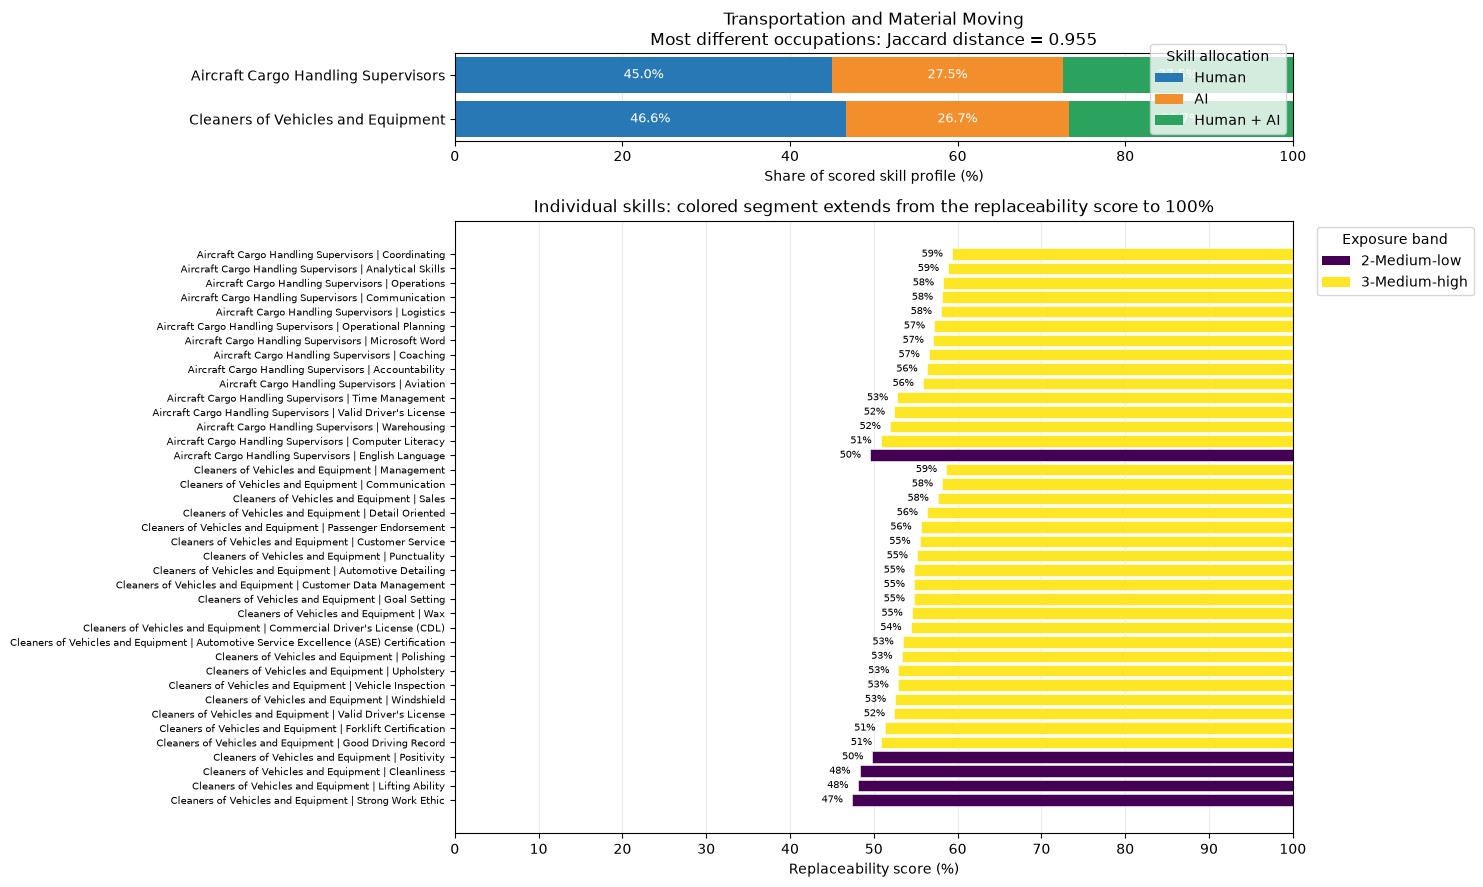


GROUP: Transportation and Material Moving
Jaccard distance: 0.955

Aircraft Cargo Handling Supervisors (53-1041.00)
Scored skills: 15 / 21
Share of original posting-weight covered by scored skills: 78.4%

Cleaners of Vehicles and Equipment (53-7061.00)
Scored skills: 24 / 25
Share of original posting-weight covered by scored skills: 96.8%

Skills missing valid scores:
Consensus Decision Making, Disciplinary Procedures, Hazardous Material Identification, Policy Implementation, Project Implementation, Resource Allocation, Sanitization


In [25]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from itertools import combinations

# ============================================================
# 1. LOAD AND PREPARE THE DATA
# ============================================================

df = pd.read_csv("lc_occupation_skills.csv")
scores = pd.read_csv("skill_replaceability_scores.csv")

# Match the same time period and geography for all occupations.
df = df[
    (df["year"] == 2023)
    & (df["period"] == "Full year")
    & (df["geography"] == "US")
].copy()

# Ensure occupation codes are strings.
df["onet"] = df["onet"].astype(str)

# Keep one row per occupation-skill combination.
df = df.drop_duplicates(
    subset=["onet", "onet_name", "skill_name"]
)

# Merge replaceability scores into the occupation data.
# Use skill_id when possible, because it is a more reliable key
# than skill_name alone.
score_columns = [
    "skill_id",
    "replaceability_score",
    "exposure_band",
]

scores = scores[score_columns].drop_duplicates(
    subset=["skill_id"]
)

df = df.merge(
    scores,
    on="skill_id",
    how="left",
    validate="many_to_one"
)

df["replaceability_score"] = pd.to_numeric(
    df["replaceability_score"], errors="coerce"
)

# Keep only valid scores for the calculations.
# Do not convert missing scores to zero.
df["valid_score"] = (
    df["replaceability_score"].between(0, 100)
)

print("Occupation-skill records:", len(df))
print("Unique occupations:", df["onet"].nunique())
print(
    "Records with valid replaceability scores:",
    int(df["valid_score"].sum())
)
print(
    "Records without valid scores:",
    int((~df["valid_score"]).sum())
)

# ============================================================
# 2. BUILD EACH OCCUPATION'S SKILL SET
# ============================================================

jobs = (
    df.groupby(["onet", "onet_name"])["skill_name"]
    .apply(lambda skills: set(skills.dropna()))
    .reset_index(name="skills")
)

print("\nExample occupations:")
print(jobs[["onet", "onet_name"]].head())


# ============================================================
# 3. SELECT THE TWO MOST DIFFERENT OCCUPATIONS IN A GROUP
# ============================================================

def select_most_different_pair(major_prefix):
    """
    Find the two occupations in a major SOC group with the
    greatest Jaccard distance between their skill sets.

    Jaccard distance = 1 - (shared skills / total distinct skills)
    A larger distance means fewer shared skills.
    """

    group_jobs = jobs[
        jobs["onet"].str.startswith(major_prefix + "-")
    ]

    candidates = [
        (
            (row["onet"], row["onet_name"]),
            row["skills"]
        )
        for _, row in group_jobs.iterrows()
    ]

    if len(candidates) < 2:
        print(
            f"Not enough occupations for major group {major_prefix}."
        )
        return None

    best_pair = None
    best_distance = -1

    for (job_a, skills_a), (job_b, skills_b) in combinations(
        candidates, 2
    ):
        union = skills_a | skills_b

        if not union:
            continue

        distance = 1 - len(skills_a & skills_b) / len(union)

        if distance > best_distance:
            best_distance = distance
            best_pair = (job_a, job_b)

    if best_pair is None:
        return None

    return best_pair[0], best_pair[1], best_distance


# ============================================================
# 4. DRAW THE TWO GRAPHS FOR ONE MAJOR OCCUPATION GROUP
# ============================================================

CATEGORY_COLORS = {
    "Human": "#2878B5",       # Blue
    "AI": "#F28E2B",          # Orange
    "Human + AI": "#2CA25F",  # Green
}


def plot_group(major_prefix, group_name):
    result = select_most_different_pair(major_prefix)

    if result is None:
        return

    job_a, job_b, distance = result
    selected_jobs = [job_a, job_b]

    # Filter to the selected two occupations.
    selected = df[
        df.apply(
            lambda row: (
                row["onet"], row["onet_name"]
            ) in selected_jobs,
            axis=1
        )
    ].copy()

    selected = selected.drop_duplicates(
        subset=["onet", "onet_name", "skill_name"]
    )

    # --------------------------------------------------------
    # Calculate how much of the skill profile has valid scores.
    # --------------------------------------------------------

    selected["pct_postings"] = pd.to_numeric(
        selected["pct_postings"], errors="coerce"
    )

    selected["pct_postings"] = selected[
        "pct_postings"
    ].clip(lower=0)

    total_weight = selected.groupby(
        ["onet", "onet_name"]
    )["pct_postings"].transform("sum")

    selected["all_skill_weight"] = np.where(
        total_weight > 0,
        selected["pct_postings"] / total_weight,
        np.nan
    )

    coverage = (
        selected.assign(
            scored_weight=np.where(
                selected["valid_score"],
                selected["all_skill_weight"],
                0
            )
        )
        .groupby(["onet", "onet_name"])
        .agg(
            total_skills=("skill_name", "nunique"),
            scored_skills=("valid_score", "sum"),
            scored_weight=("scored_weight", "sum")
        )
    )

    # --------------------------------------------------------
    # Use only skills with valid scores for the graphs.
    # Renormalize their weights to sum to 100% per occupation.
    # --------------------------------------------------------

    scored = selected[
        selected["valid_score"]
        & selected["all_skill_weight"].notna()
    ].copy()

    if scored.empty:
        print(f"No scored skills for {group_name}.")
        return

    scored_total = scored.groupby(
        ["onet", "onet_name"]
    )["pct_postings"].transform("sum")

    scored["skill_weight"] = np.where(
        scored_total > 0,
        scored["pct_postings"] / scored_total,
        np.nan
    )

    scored = scored.dropna(subset=["skill_weight"])

    # --------------------------------------------------------
    # Split every skill into Human, AI, and Human + AI.
    #
    # Example:
    # Skill weight = 25%, replaceability score = 80%
    #
    # Human       = 25% * (1 - .80) = 5%
    # AI          = 25% * .80 * .50 = 10%
    # Human + AI  = 25% * .80 * .50 = 10%
    # --------------------------------------------------------

    score_fraction = scored["replaceability_score"] / 100

    scored["Human"] = (
        scored["skill_weight"]
        * (1 - score_fraction)
        * 100
    )

    scored["AI"] = (
        scored["skill_weight"]
        * score_fraction
        * 50
    )

    scored["Human + AI"] = (
        scored["skill_weight"]
        * score_fraction
        * 50
    )

    # --------------------------------------------------------
    # GRAPH 1: 100% stacked horizontal bars for the two jobs.
    # --------------------------------------------------------

    category_totals = scored.groupby(
        ["onet", "onet_name"]
    )[["Human", "AI", "Human + AI"]].sum()

    ordered_index = pd.MultiIndex.from_tuples(
        selected_jobs,
        names=["onet", "onet_name"]
    )

    category_totals = category_totals.reindex(ordered_index)

    labels = [job[1] for job in selected_jobs]
    fig_height = max(8, len(scored) * 0.23)

    fig, (ax_job, ax_skill) = plt.subplots(
        2,
        1,
        figsize=(15, fig_height),
        gridspec_kw={"height_ratios": [1, max(4, len(scored) * 0.18)]}
    )

    left = np.zeros(len(labels))

    for category in ["Human", "AI", "Human + AI"]:
        values = category_totals[category].fillna(0).to_numpy()

        ax_job.barh(
            labels,
            values,
            left=left,
            color=CATEGORY_COLORS[category],
            label=category
        )

        for i, value in enumerate(values):
            if value >= 7:
                ax_job.text(
                    left[i] + value / 2,
                    i,
                    f"{value:.1f}%",
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=9
                )

        left += values

    ax_job.set_xlim(0, 100)
    ax_job.set_xlabel(
        "Share of scored skill profile (%)"
    )
    ax_job.set_title(
        f"{group_name}\n"
        f"Most different occupations: "
        f"Jaccard distance = {distance:.3f}"
    )
    ax_job.legend(
        title="Skill allocation",
        loc="lower right"
    )
    ax_job.grid(axis="x", alpha=0.25)
    ax_job.set_axisbelow(True)
    ax_job.invert_yaxis()

    # --------------------------------------------------------
    # GRAPH 2: Individual skills, from their score to 100%.
    #
    # A score of 60 produces a bar from x = 60 to x = 100.
    # The bar's length is therefore 100 - score.
    # --------------------------------------------------------

    scored = scored.sort_values(
        ["onet_name", "replaceability_score", "skill_name"],
        ascending=[True, False, True]
    ).reset_index(drop=True)

    y = np.arange(len(scored))
    skill_scores = scored["replaceability_score"].to_numpy()

    scored["skill_label"] = (
        scored["onet_name"] + " | " + scored["skill_name"]
    )

    bands = (
        scored["exposure_band"]
        .fillna("Unknown")
        .astype(str)
    )

    unique_bands = sorted(bands.unique())
    cmap = plt.get_cmap("viridis", max(len(unique_bands), 1))

    band_colors = {
        band: cmap(i)
        for i, band in enumerate(unique_bands)
    }

    colors = [band_colors[band] for band in bands]

    ax_skill.barh(
        y,
        100 - skill_scores,
        left=skill_scores,
        color=colors,
        edgecolor="white",
        linewidth=0.4
    )

    # Put the actual score just to the left of the bar.
    for ypos, score in zip(y, skill_scores):
        ax_skill.text(
            max(score - 1, 0),
            ypos,
            f"{score:.0f}%",
            ha="right" if score > 8 else "left",
            va="center",
            fontsize=7
        )

    ax_skill.set_yticks(y)
    ax_skill.set_yticklabels(
        scored["skill_label"],
        fontsize=7
    )

    ax_skill.set_xlim(0, 100)
    ax_skill.set_xticks(np.arange(0, 101, 10))
    ax_skill.set_xlabel("Replaceability score (%)")
    ax_skill.set_title(
        "Individual skills: colored segment extends from "
        "the replaceability score to 100%"
    )
    ax_skill.grid(axis="x", alpha=0.25)
    ax_skill.set_axisbelow(True)
    ax_skill.invert_yaxis()

    ax_skill.legend(
        handles=[
            Patch(facecolor=band_colors[band], label=band)
            for band in unique_bands
        ],
        title="Exposure band",
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

    # --------------------------------------------------------
    # PRINT THE OCCUPATIONS AND THEIR SCORE COVERAGE.
    # --------------------------------------------------------

    print(f"\n{'=' * 65}")
    print(f"GROUP: {group_name}")
    print(f"Jaccard distance: {distance:.3f}")

    for code, name in selected_jobs:
        if (code, name) in coverage.index:
            info = coverage.loc[(code, name)]

            print(f"\n{name} ({code})")
            print(
                f"Scored skills: {int(info['scored_skills'])}"
                f" / {int(info['total_skills'])}"
            )
            print(
                "Share of original posting-weight covered by "
                f"scored skills: {info['scored_weight'] * 100:.1f}%"
            )

    missing = selected[
        ~selected["valid_score"]
    ]["skill_name"].dropna().unique()

    if len(missing):
        print("\nSkills missing valid scores:")
        print(", ".join(sorted(missing.astype(str))))


# ============================================================
# 5. GENERATE GRAPHS FOR ALL 11 MAJOR OCCUPATION GROUPS
# ============================================================

plot_group("11", "Management and Executive Occupations")
plot_group("13", "Business and Financial Operations")
plot_group("15", "Computer and Information Technology")
plot_group("17", "Architecture and Engineering")
plot_group("19", "Life, Physical, and Social Science")
plot_group("29", "Healthcare Practitioners")
plot_group("25", "Education, Training, and Library")
plot_group("27", "Arts, Design, Entertainment, Sports, and Media")
plot_group("41", "Sales and Related Occupations")
plot_group("47", "Construction and Extraction")
plot_group("53", "Transportation and Material Moving")
